In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import datetime

from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Fixed seed so the results can be reproduced
SEED = 1

In [2]:
# Load the data

In [3]:
data_raw = pd.read_csv('https://drive.google.com/uc?export=download&id=1xtwMAFoVFV2FCAahPrCswBljut09eK1i')
data_raw.head(3)
# The URL is a direct-download link to the CSV stored on Google Drive (file id 1xtwMAFoVFV2FCAahPrCswBljut09eK1i)
# Source: https://www.kaggle.com/datasets/ninopadilla13/employee-churn/data
# Original source: https://elitedatascience.com/

,avg_monthly_hrs,department,filed_complaint,last_evaluation,n_projects,recently_promoted,salary,satisfaction,status,tenure
0,221,engineering,NaN,0.932868,4,NaN,low,0.829896,Left,5.0
1,232,support,NaN,NaN,3,NaN,low,0.834544,Employed,2.0
2,184,sales,NaN,0.788830,3,NaN,medium,0.834988,Employed,3.0


In [4]:
data_raw.status.value_counts()

status
Employed    10857
Left         3392
Name: count, dtype: int64

In [5]:
data_raw.info()
# Cleaning plan:
# 1. department: fill with the mode
# 2. filed_complaint: fill with 0
# 3. last_evaluation: fill with the department mean, or the overall mean if departments do not differ
# 5. recently_promoted: drop, too much missing data
# 7, 9. satisfaction and tenure: fill with the department average

<class 'pandas.DataFrame'>
RangeIndex: 14249 entries, 0 to 14248
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   avg_monthly_hrs    14249 non-null  int64  
 1   department         13540 non-null  str    
 2   filed_complaint    2058 non-null   float64
 3   last_evaluation    12717 non-null  float64
 4   n_projects         14249 non-null  int64  
 5   recently_promoted  300 non-null    float64
 6   salary             14249 non-null  str    
 7   satisfaction       14068 non-null  float64
 8   status             14249 non-null  str    
 9   tenure             14068 non-null  float64
dtypes: float64(5), int64(2), str(3)
memory usage: 1.1 MB


In [6]:
data_raw.describe()

,avg_monthly_hrs,filed_complaint,last_evaluation,n_projects,recently_promoted,satisfaction,tenure
count,14249.000000,2058.0,12717.000000,14249.000000,300.0,14068.000000,14068.000000
mean,199.795775,1.0,0.718477,3.773809,1.0,0.621295,3.497228
std,50.998714,0.0,0.173062,1.253126,0.0,0.250469,1.460917
min,49.000000,1.0,0.316175,1.000000,1.0,0.040058,2.000000
25%,155.000000,1.0,0.563866,3.000000,1.0,0.450390,3.000000
50%,199.000000,1.0,0.724939,4.000000,1.0,0.652527,3.000000
75%,245.000000,1.0,0.871358,5.000000,1.0,0.824951,4.000000
max,310.000000,1.0,1.000000,7.000000,1.0,1.000000,10.000000


# **EDA**

In [7]:
#Create a copy to EDA
eda=data_raw.copy()

Text(0.5, 1.0, 'n_projects')

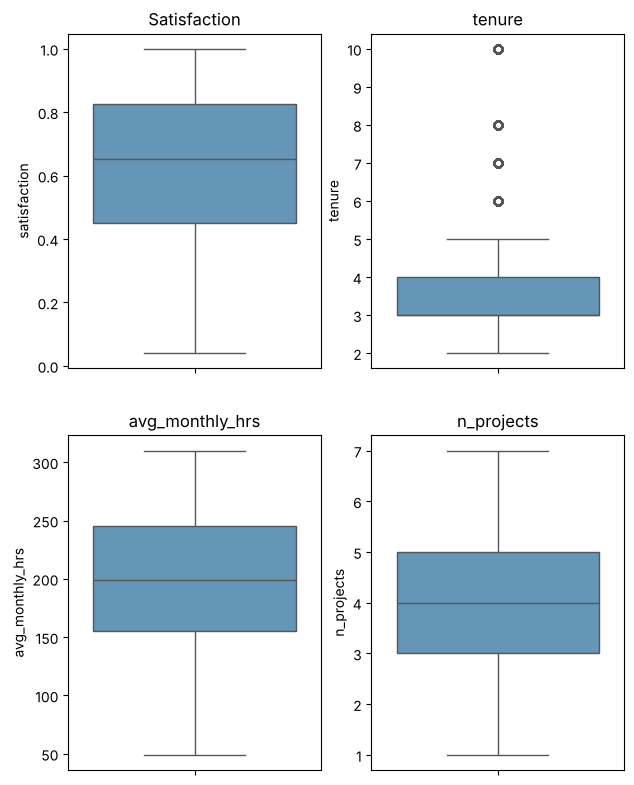

In [8]:
plt.figure(figsize=(15,20))
plt.subplot2grid((4,4),(0,0))
sns.boxplot(y = eda.satisfaction,color='#5799c6')
plt.title('Satisfaction')
plt.subplot2grid((4,4),(0,1))
sns.boxplot(y=eda.tenure,color='#5799c6')
plt.title('tenure')
plt.subplot2grid((4,4),(1,0))
sns.boxplot(y=eda.avg_monthly_hrs,color='#5799c6')
plt.title('avg_monthly_hrs')
plt.subplot2grid((4,4),(1,1))
sns.boxplot(y=eda.n_projects,color='#5799c6')
plt.title('n_projects')
# satisfaction, avg_monthly_hrs and n_projects have no outliers, so they can be filled with the mean
# tenure could also be filled with the mean, but needs further checking

Text(0, 0.5, 'Percentage')

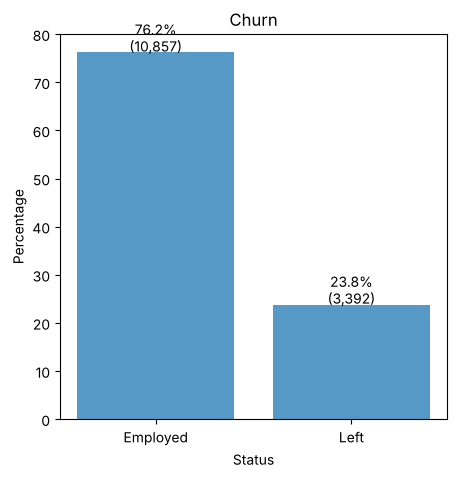

In [9]:
plt.figure(figsize=(5,5))
churn_counts = eda['status'].value_counts()
churn_percentages = churn_counts / len(eda) * 100

plt.bar(churn_percentages.index, churn_percentages.values, color='#5799c6')
for i, (pct, count) in enumerate(zip(churn_percentages.values, churn_counts.values)):
    plt.text(i, pct + 0.2, f"{pct:.1f}%\n({count:,})", ha='center')

plt.title('Churn')
plt.xlabel('Status')
plt.ylabel('Percentage')

Text(0.5, 0, 'Department')

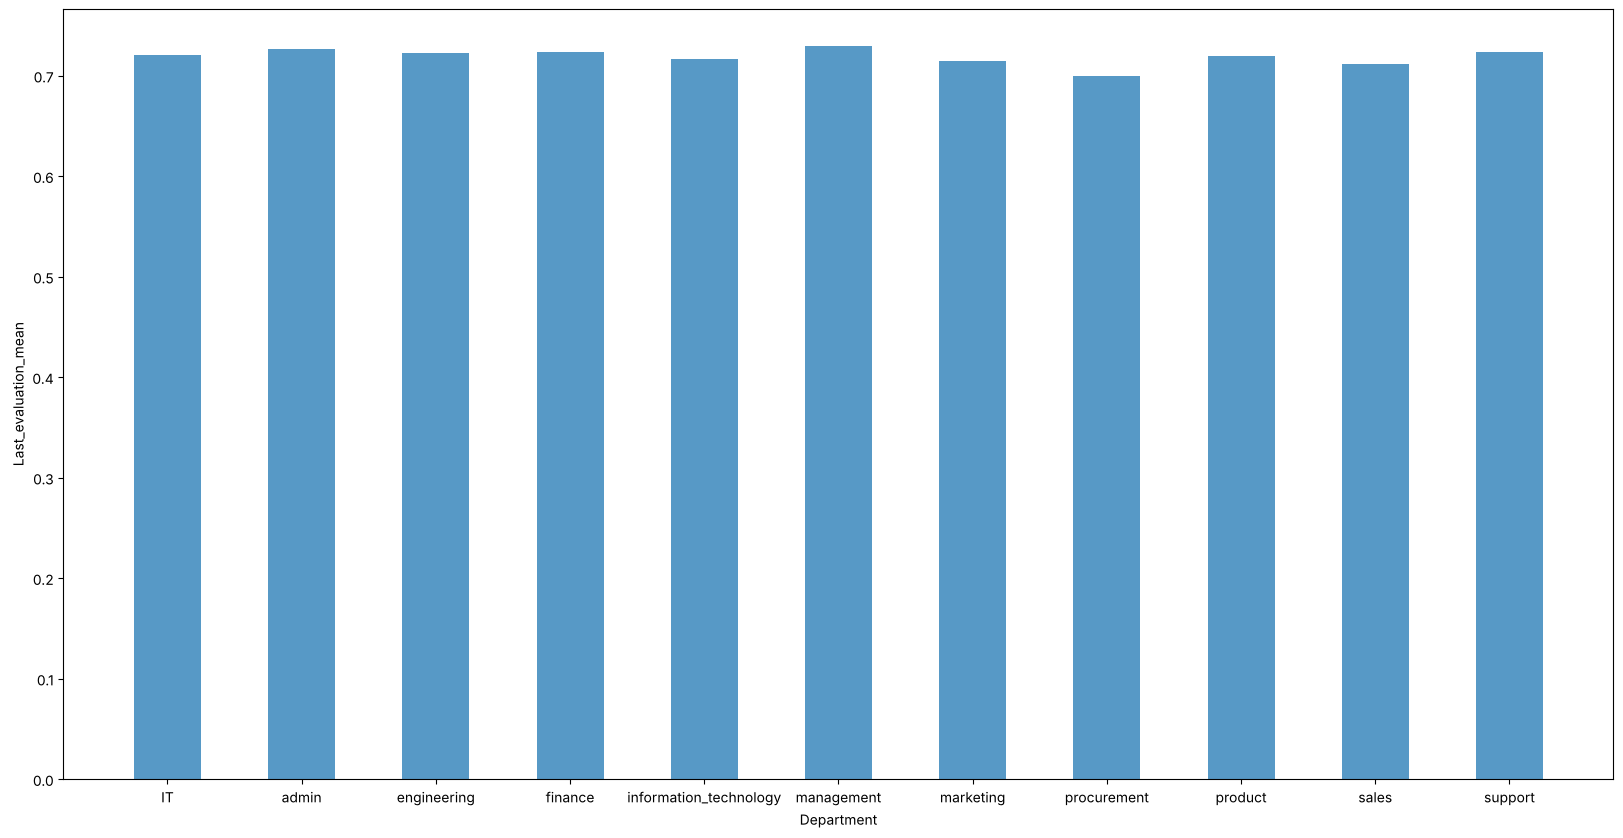

In [10]:
mean_last_evaluation = eda.groupby('department')['last_evaluation'].mean()
plt.figure(figsize=(20, 10))
index = mean_last_evaluation.index

plt.bar(index, mean_last_evaluation.values, 0.5,color='#5799c6')
plt.ylabel('Last_evaluation_mean')
plt.xlabel('Department')
# => no real difference between departments, so we can fill with the overall mean

In [11]:
eda.head(3)

,avg_monthly_hrs,department,filed_complaint,last_evaluation,n_projects,recently_promoted,salary,satisfaction,status,tenure
0,221,engineering,NaN,0.932868,4,NaN,low,0.829896,Left,5.0
1,232,support,NaN,NaN,3,NaN,low,0.834544,Employed,2.0
2,184,sales,NaN,0.788830,3,NaN,medium,0.834988,Employed,3.0


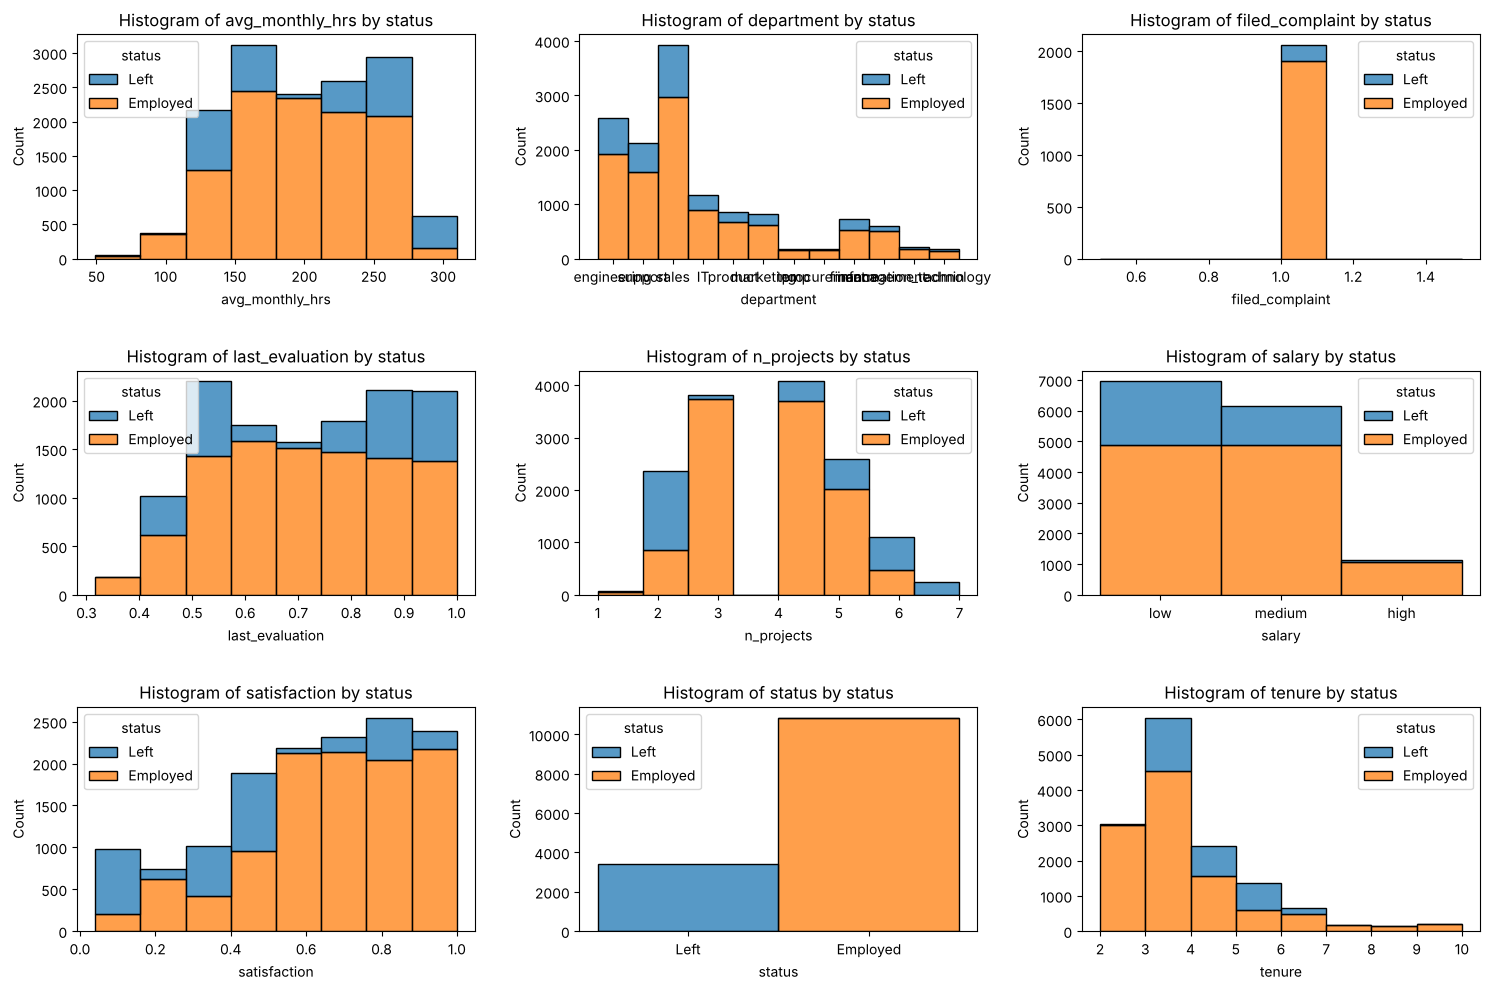

In [12]:
# Graph subplot
fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(15, 10))

# Create a loop for each features
features = ['avg_monthly_hrs', 'department', 'filed_complaint', 'last_evaluation', 'n_projects', 'salary',
       'satisfaction', 'status', 'tenure']
for i, feature in enumerate(features):
    row, col = divmod(i, 3)
    sns.histplot(data=eda, x=feature, hue='status', multiple='stack', bins=8, ax=axs[row, col])
    axs[row, col].set_title(f'Histogram of {feature} by status')

# Change layout
plt.tight_layout()

# Add space between the subplot titles and the charts
plt.subplots_adjust(hspace=0.5)
plt.show()

# **Data Cleaning**

In [13]:
cleaning=data_raw.copy()

In [14]:
cleaning.drop_duplicates(inplace=True)

In [15]:
# Fill missing department with the mode
cleaning['department'] = cleaning['department'].fillna(cleaning['department'].mode()[0])

In [16]:
# Drop recently_promoted: too much missing data to recover
cleaning.drop('recently_promoted',axis=1,inplace=True)

In [17]:
department_satisfaction_dict = cleaning.groupby('department')['satisfaction'].mean().to_dict()
department_satisfaction_dict

{'IT': 0.6283242200964685,
 'admin': 0.6114500250625,
 'engineering': 0.6179074420262346,
 'finance': 0.5867869613612637,
 'information_technology': 0.6267165012918661,
 'management': 0.6304275287361344,
 'marketing': 0.6291215213675214,
 'procurement': 0.6279296998218391,
 'product': 0.6287741562906977,
 'sales': 0.620210169578152,
 'support': 0.6269226474542884,
 'temp': nan}

In [18]:
index_null_temp = cleaning["satisfaction"][cleaning["satisfaction"].isnull()].index

In [19]:
# satisfaction and tenure are all missing for the 'temp' department
cleaning.loc[index_null_temp, ['satisfaction', 'department','tenure','last_evaluation']].head(3)

,satisfaction,department,tenure,last_evaluation
24,NaN,temp,NaN,NaN
28,NaN,temp,NaN,NaN
44,NaN,temp,NaN,NaN


In [20]:
# Drop the 'temp' department: filling these rows with the mean would not make sense
cleaning.drop(cleaning[cleaning['department'] == 'temp'].index,inplace = True)

In [21]:
# Fill filed_complaint with 0: a missing value most likely means no complaint was filed
values = {"filed_complaint": 0}
cleaning.fillna(value=values,inplace=True)

,avg_monthly_hrs,department,filed_complaint,last_evaluation,n_projects,salary,satisfaction,status,tenure
0,221,engineering,0.0,0.932868,4,low,0.829896,Left,5.0
1,232,support,0.0,NaN,3,low,0.834544,Employed,2.0
2,184,sales,0.0,0.788830,3,medium,0.834988,Employed,3.0
3,206,sales,0.0,0.575688,4,low,0.424764,Employed,2.0
4,249,sales,0.0,0.845217,3,low,0.779043,Employed,3.0
...,...,...,...,...,...,...,...,...,...
14244,178,IT,0.0,0.735865,5,low,0.263282,Employed,5.0
14245,257,sales,0.0,0.638604,3,low,0.868209,Employed,2.0
14246,232,finance,1.0,0.847623,5,medium,0.898917,Left,5.0
14247,130,IT,0.0,0.757184,4,medium,0.641304,Employed,3.0


In [22]:
cleaning.info()

<class 'pandas.DataFrame'>
Index: 14068 entries, 0 to 14248
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   avg_monthly_hrs  14068 non-null  int64  
 1   department       14068 non-null  str    
 2   filed_complaint  14068 non-null  float64
 3   last_evaluation  12717 non-null  float64
 4   n_projects       14068 non-null  int64  
 5   salary           14068 non-null  str    
 6   satisfaction     14068 non-null  float64
 7   status           14068 non-null  str    
 8   tenure           14068 non-null  float64
dtypes: float64(4), int64(2), str(3)
memory usage: 1.1 MB


In [23]:
index_null_last_evaluation = cleaning["last_evaluation"][cleaning["last_evaluation"].isnull()].index

In [24]:
# Earlier version filled by department mean:
# cleaning['last_evaluation'] = cleaning['last_evaluation'].fillna(cleaning.groupby('department')['last_evaluation'].transform('mean'))

cleaning['last_evaluation'] = cleaning['last_evaluation'].fillna(cleaning['last_evaluation'].mean())

In [25]:
cleaning.loc[index_null_last_evaluation, ['last_evaluation']].head(1)

,last_evaluation
1,0.718477


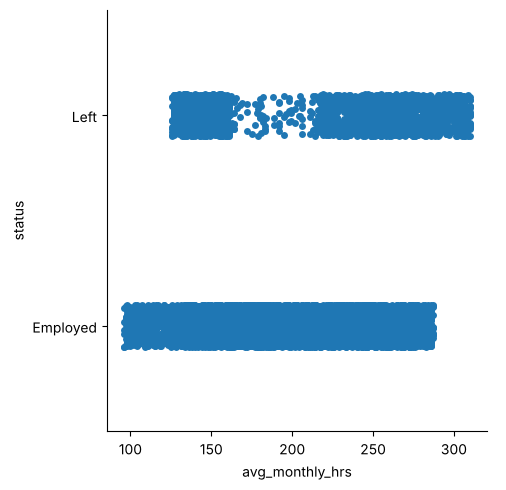

In [26]:
sns.catplot(x="avg_monthly_hrs",y="status",data=cleaning)

In [27]:
cleaning_left=cleaning[(cleaning.status=="Left")]

In [28]:
cleaning_employed=cleaning[(cleaning.status=="Employed")]

<Axes: ylabel='avg_monthly_hrs'>

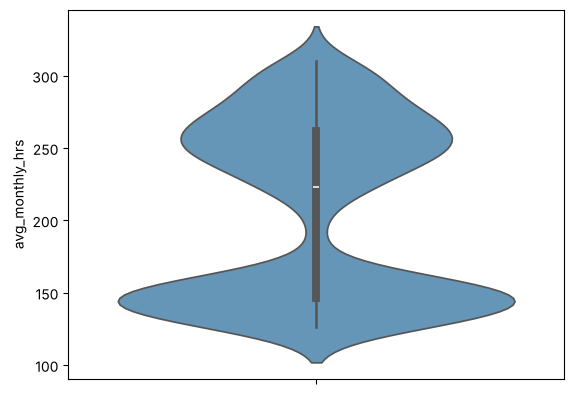

In [29]:
sns.violinplot(cleaning_left["avg_monthly_hrs"],color='#5799c6')

<Axes: ylabel='n_projects'>

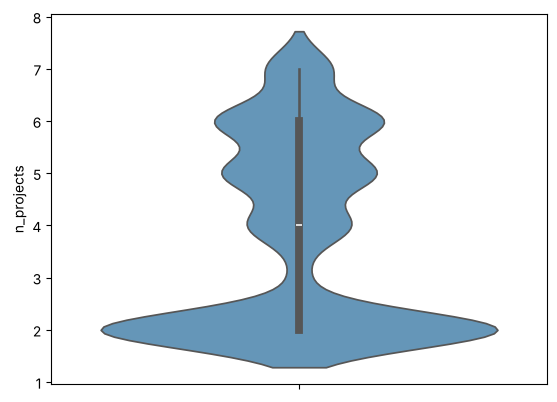

In [30]:
sns.violinplot(cleaning_left["n_projects"],color='#5799c6')

# **Base model**

In [31]:
model_data=cleaning.copy()

In [32]:
model_data.head(3)

,avg_monthly_hrs,department,filed_complaint,last_evaluation,n_projects,salary,satisfaction,status,tenure
0,221,engineering,0.0,0.932868,4,low,0.829896,Left,5.0
1,232,support,0.0,0.718477,3,low,0.834544,Employed,2.0
2,184,sales,0.0,0.788830,3,medium,0.834988,Employed,3.0


In [33]:
encode1 = OrdinalEncoder(categories=[['low', 'medium', 'high']])

In [34]:
encoded_data = encode1.fit_transform(model_data[['salary']])

In [35]:
model_data['salary'] = encoded_data

In [36]:
encode1.categories_

[array(['low', 'medium', 'high'], dtype=object)]

In [37]:
model_data['department'].nunique()
# 11 unique departments: which encoding should we use?

11

In [38]:
# For now, use an ordinal encoder ordered from the least to the most frequent department
department_count = model_data['department'].value_counts()
reversed_departments = department_count[::-1]
reversed_list = reversed_departments.index.tolist()
reversed_list

['procurement',
 'admin',
 'information_technology',
 'management',
 'finance',
 'marketing',
 'product',
 'IT',
 'support',
 'engineering',
 'sales']

In [39]:
encode_2 = OrdinalEncoder(categories=[['procurement',
 'admin',
 'information_technology',
 'management',
 'finance',
 'marketing',
 'product',
 'IT',
 'support',
 'engineering',
 'sales']])

In [40]:
encode_data_2 = encode_2.fit_transform(model_data[['department']])

In [41]:
model_data['department'] = encode_data_2

## Model loop: compare five classifiers

In [42]:
models = [LogisticRegression(max_iter=1000),
    DecisionTreeClassifier(max_depth=2, random_state=SEED),
    RandomForestClassifier(n_estimators=5, random_state=SEED),
    SVC(),
    KNeighborsClassifier(n_neighbors=2)]
precision=[]
recall=[]
f1=[]
time=[]
name=[]

In [43]:
x = model_data.drop(columns=['status'])
y = model_data['status']
x_train , x_valid, y_train , y_valid = train_test_split(x , y , test_size = 0.2, random_state = SEED)

In [44]:
for model in models:
  t1 = datetime.datetime.now()
  model_name = model.__class__.__name__
  model.fit(x_train, y_train)
  t2 = datetime.datetime.now()
  d = round((t2 - t1).total_seconds() * 1000, 1)  # training time in milliseconds
  y_pred = model.predict(x_valid)
  # Scores for the 'Left' class: the employees we want to catch
  pre = round(precision_score(y_valid, y_pred, pos_label='Left'), 2)
  rec = round(recall_score(y_valid, y_pred, pos_label='Left'), 2)
  f1_ = round(f1_score(y_valid, y_pred, pos_label='Left'), 2)
  precision.append(pre)
  recall.append(rec)
  f1.append(f1_)
  time.append(d)
  name.append(model_name)

In [45]:
Results = pd.DataFrame({'Name': name, 'Precision': precision, 'Recall': recall, 'F1-score': f1, 'Time (ms)': time})
Results
# => Random Forest performs best

,Name,Precision,Recall,F1-score,Time (ms)
0,LogisticRegression,0.64,0.36,0.46,169.8
1,DecisionTreeClassifier,0.85,0.40,0.54,14.7
2,RandomForestClassifier,0.96,0.92,0.94,48.2
3,SVC,1.00,0.10,0.19,2421.7
4,KNeighborsClassifier,0.92,0.87,0.89,15.5


# **Improve model**

In [46]:
# Lower the decision threshold from 0.5 to 0.4 so the model flags more employees who might leave

In [47]:
model = RandomForestClassifier(n_estimators=10, random_state=SEED)
model.fit(x_train, y_train)

y_pred = model.predict(x_valid)
y_pred_prob = model.predict_proba(x_valid)  # column 1 = probability of 'Left'

In [48]:
result = []
for i in range(len(y_pred_prob)):
  if (y_pred_prob[i,1] < 0.4):
    result.append("Employed")
  else:
    result.append("Left")
result_forest = np.array(result)
# classification_report(y_true, y_pred): true labels first, predictions second
print(classification_report(y_valid, result_forest))

              precision    recall  f1-score   support

    Employed       0.98      0.98      0.98      2109
        Left       0.95      0.92      0.94       705

    accuracy                           0.97      2814
   macro avg       0.96      0.95      0.96      2814
weighted avg       0.97      0.97      0.97      2814



In [49]:
#encode status to draw correlation
model_data_full_encode = model_data.copy()
encode_3 = OrdinalEncoder(categories=[['Employed', 'Left']])
encoded_data_3 = encode_3.fit_transform(model_data[['status']])
model_data_full_encode['status'] = encoded_data_3
encode_3.categories_

[array(['Employed', 'Left'], dtype=object)]

<Axes: >

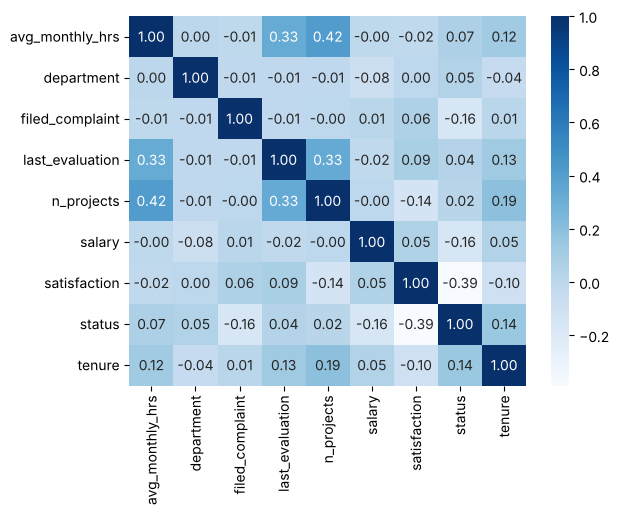

In [50]:
sns.heatmap(model_data_full_encode.corr(), annot=True, cmap='Blues', fmt='.2f')
# Correlation with status is highest for filed_complaint, salary, satisfaction and tenure => train the random forest on these features

In [51]:
x_improve = model_data[['filed_complaint','salary','satisfaction','tenure','department']]
y_improve = model_data['status']
x_train_improve , x_valid_improve , y_train_improve , y_valid_improve = train_test_split(x_improve , y_improve , test_size = 0.2, random_state = SEED)

In [52]:
model_forest_improve = RandomForestClassifier(n_estimators=10, random_state=SEED)
model_forest_improve.fit(x_train_improve, y_train_improve)

y_pred_improve = model_forest_improve.predict(x_valid_improve)
y_pred_prob_improve = model_forest_improve.predict_proba(x_valid_improve)

In [53]:
result_improve = []
for i in range(len(y_pred_prob_improve)):
  if (y_pred_prob_improve[i,1] < 0.4):
    result_improve.append("Employed")
  else:
    result_improve.append("Left")
result_forest_improve = np.array(result_improve)
print(classification_report(y_valid_improve, result_forest_improve))

# Using only 5 features gives a simpler model, at the cost of some accuracy.
# Recall in the base model is already high, so the data was not rebalanced
# (balancing with SMOTE was tested and made the model worse).

              precision    recall  f1-score   support

    Employed       0.95      0.92      0.93      2109
        Left       0.78      0.86      0.82       705

    accuracy                           0.90      2814
   macro avg       0.86      0.89      0.88      2814
weighted avg       0.91      0.90      0.91      2814



In [54]:
# Precision, Recall and F1-score are already numeric

In [55]:
Results = Results.sort_values(by=['Recall','Precision'], ascending=False)

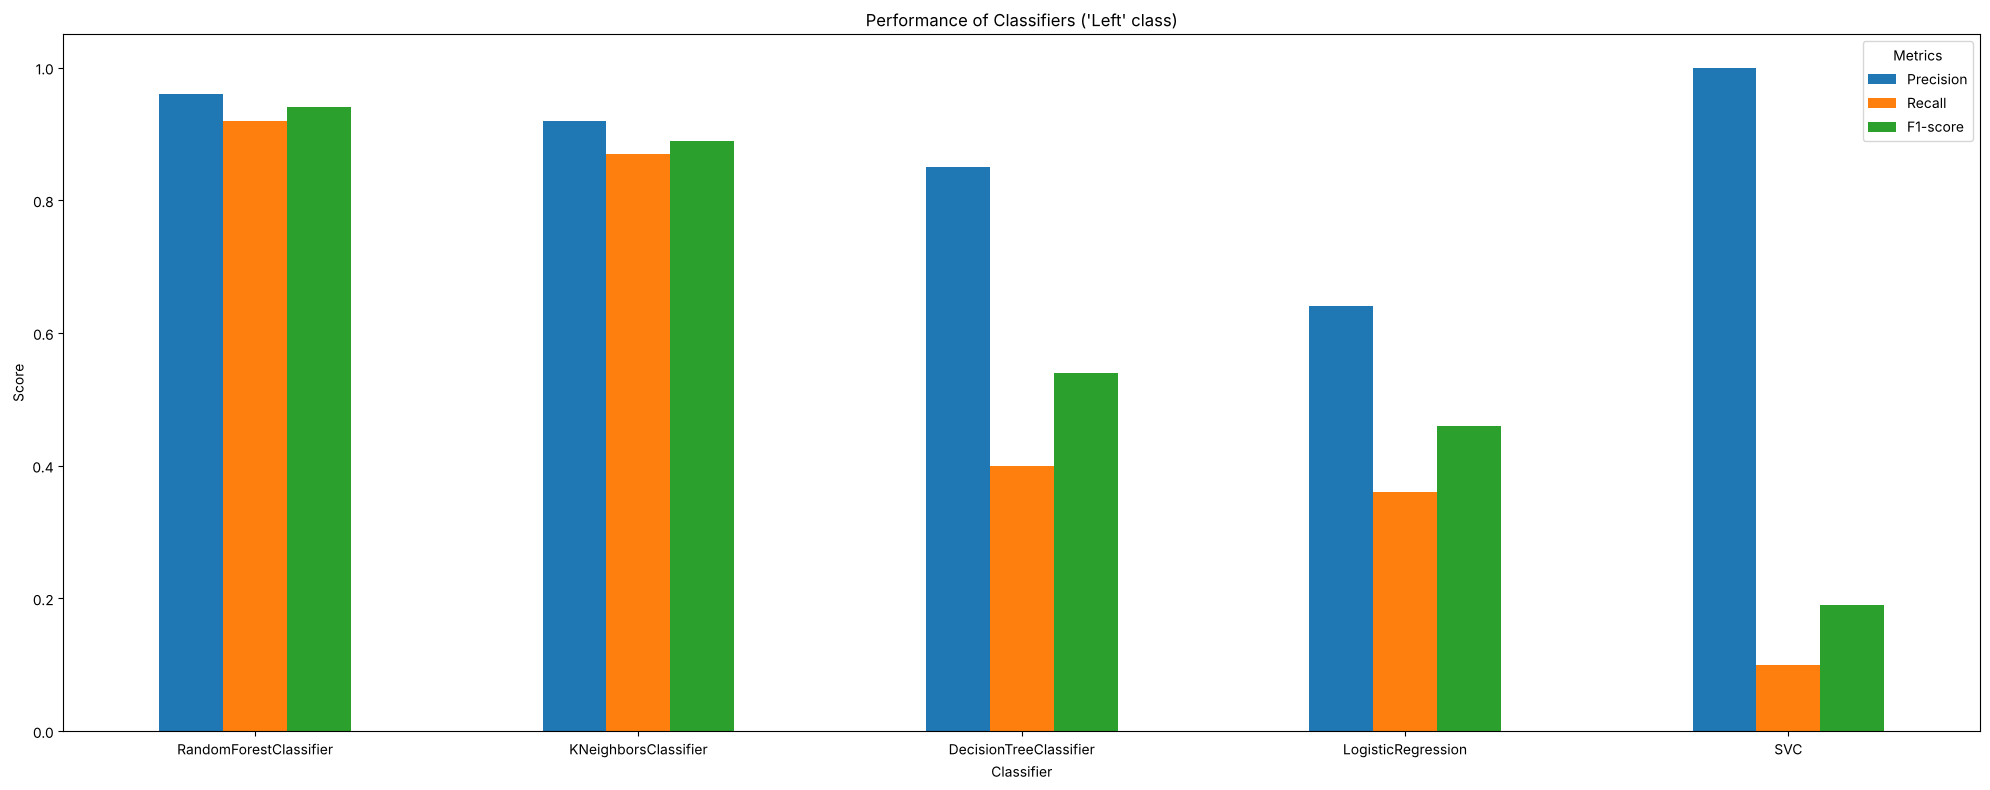

In [56]:
Results.plot.bar(
    x="Name",
    y=["Precision", "Recall", "F1-score"],
    stacked=False,
    title="Performance of Classifiers ('Left' class)",
    figsize=(20, 8))

plt.xlabel("Classifier")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()

In [57]:
# Add the two tuned models, scored on the 'Left' class like the models above
def left_scores(y_true, y_pred):
    return {'Precision': round(precision_score(y_true, y_pred, pos_label='Left'), 2),
            'Recall': round(recall_score(y_true, y_pred, pos_label='Left'), 2),
            'F1-score': round(f1_score(y_true, y_pred, pos_label='Left'), 2)}

tuned = pd.DataFrame([
    {'Name': 'RF (threshold 0.4)', **left_scores(y_valid, result_forest)},
    {'Name': 'RF+ (5 features, threshold 0.4)', **left_scores(y_valid_improve, result_forest_improve)},
])
Results = pd.concat([Results, tuned], ignore_index=True)
Results

,Name,Precision,Recall,F1-score,Time (ms)
0,RandomForestClassifier,0.96,0.92,0.94,48.2
1,KNeighborsClassifier,0.92,0.87,0.89,15.5
2,DecisionTreeClassifier,0.85,0.40,0.54,14.7
3,LogisticRegression,0.64,0.36,0.46,169.8
4,SVC,1.00,0.10,0.19,2421.7
5,RF (threshold 0.4),0.95,0.92,0.94,NaN
6,"RF+ (5 features, threshold 0.4)",0.78,0.86,0.82,NaN


In [58]:
Results = Results.sort_values(by=['Recall','Precision'], ascending=False)

In [59]:
# Keep the strongest models for the final comparison chart
Results = Results[Results['Name'].isin(['RandomForestClassifier', 'KNeighborsClassifier',
                                        'RF (threshold 0.4)', 'RF+ (5 features, threshold 0.4)'])]
Results

,Name,Precision,Recall,F1-score,Time (ms)
0,RandomForestClassifier,0.96,0.92,0.94,48.2
5,RF (threshold 0.4),0.95,0.92,0.94,NaN
1,KNeighborsClassifier,0.92,0.87,0.89,15.5
6,"RF+ (5 features, threshold 0.4)",0.78,0.86,0.82,NaN


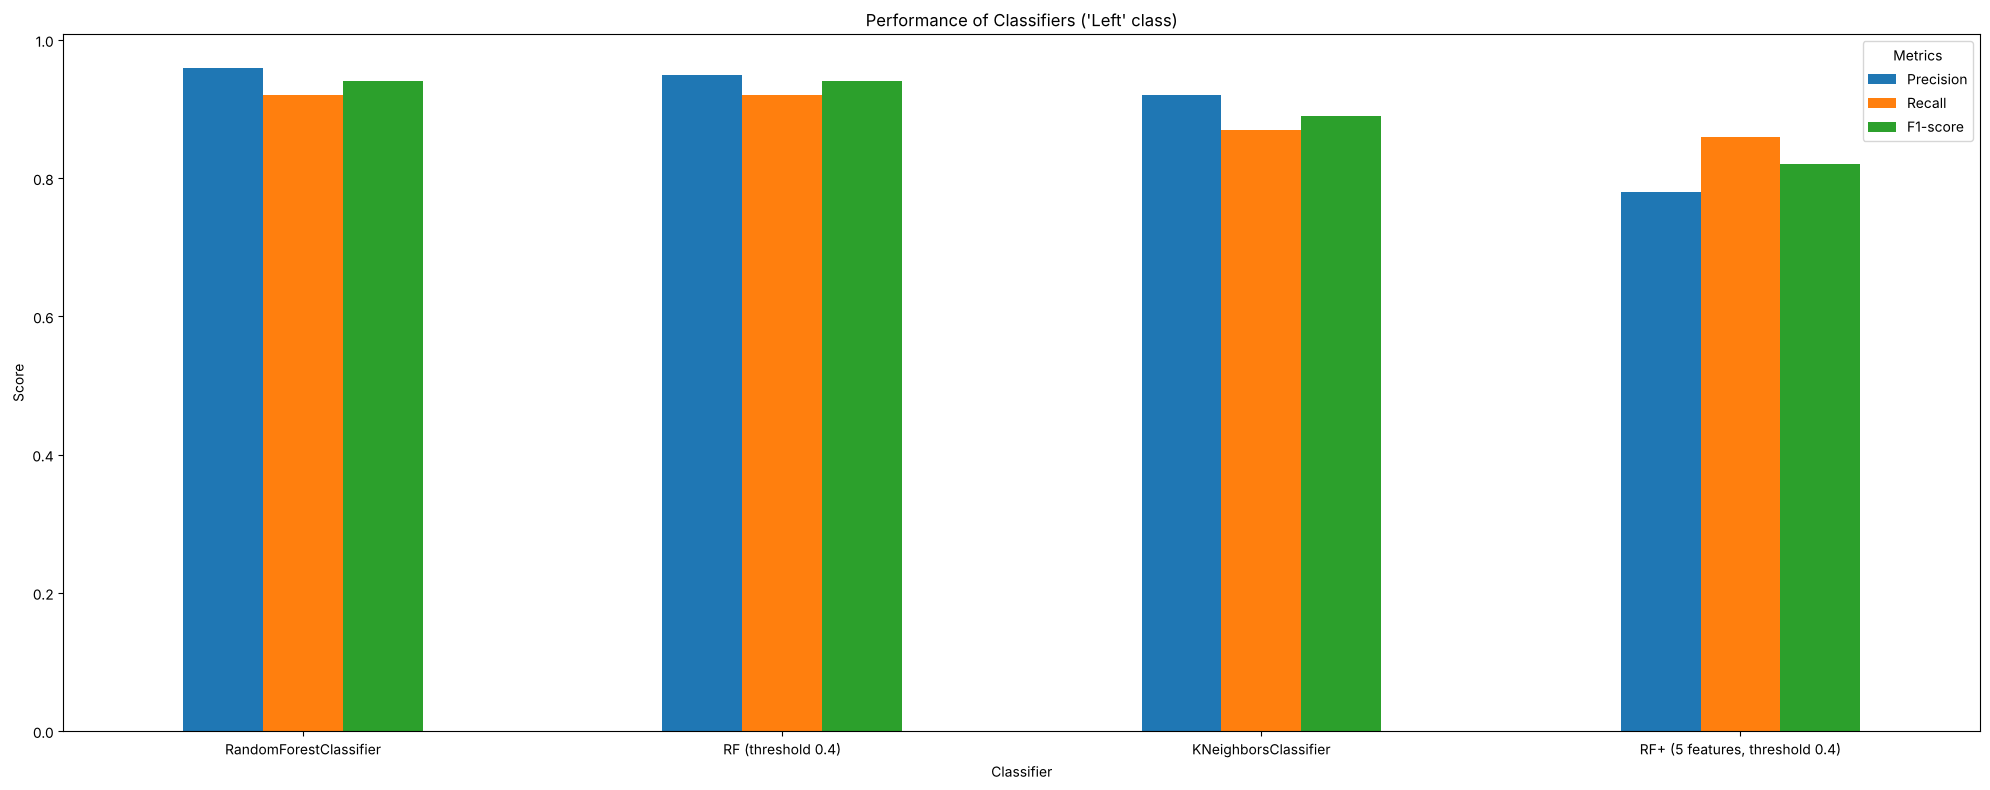

In [60]:
Results.plot.bar(
    x="Name",
    y=["Precision", "Recall", "F1-score"],
    stacked=False,
    title="Performance of Classifiers ('Left' class)",
    figsize=(20, 8))

plt.xlabel("Classifier")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()